# Непараметрические тесты (лекция 24)

Полное сопровождение лекции: теория, расчёты через `scipy.stats`, визуализация **распределения при $H_0$** и положения **score**.

По каждому тесту — **два примера** на одну и ту же постановку:
1. данные ведут к **отклонению** $H_0$;
2. данные ведут к **неотклонению** $H_0$.

Уровень значимости везде: $\alpha = 0.05$.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown
from matplotlib.patches import Patch

ALPHA = 0.05
RNG = np.random.default_rng(42)
MW_COLORS = {'A': '#4682b4', 'B': '#e74c3c'}
MW_LATEX = {'A': 'blue', 'B': 'red'}


def _fill_tail(ax, x, y, mask, **kwargs):
    if np.any(mask):
        ax.fill_between(x[mask], y[mask], **kwargs)


def print_decision(score, p_value, rule):
    reject = p_value < ALPHA
    print(f'score = {score:.4f}')
    print(f'p-value = {p_value:.6f}')
    print(rule)
    print('Решение:', 'Отклоняем H0' if reject else 'Не отклоняем H0')


def plot_right_tail(dist, df, score, crit, xlabel, title):
    x = np.linspace(0, max(score, crit) * 1.25 + 1, 600)
    y = dist.pdf(x, df)
    p_value = dist.sf(score, df)
    fig, ax = plt.subplots(figsize=(8, 4.2))
    ax.plot(x, y, lw=2, color='0.25', label=rf'при $H_0$: $\chi^2({df})$')
    ax.axvline(crit, color='tomato', ls='--', lw=2, label=rf'$K = {crit:.3f}$')
    ax.axvline(score, color='navy', lw=2.5, label=rf'$score = {score:.3f}$')
    _fill_tail(ax, x, y, x >= crit, color='tomato', alpha=0.35, label=rf'критическая зона ($\alpha$)')
    _fill_tail(ax, x, y, x >= score, color='steelblue', alpha=0.35, label=rf'p-value = {p_value:.4f}')
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Плотность')
    ax.set_title(title)
    ax.legend(loc='best', fontsize=9)
    ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()
    print_decision(score, p_value, f'Правило: отклоняем H0, если score > {crit:.3f}')


def plot_left_tail_empirical(null_scores, score, crit, xlabel, title, p_value):
    fig, ax = plt.subplots(figsize=(8, 4.2))
    ax.hist(null_scores, bins=35, density=True, color='0.85', edgecolor='0.6', label='эмпир. при $H_0$')
    ax.axvline(crit, color='tomato', ls='--', lw=2, label=rf'$K = {crit:.3f}$')
    ax.axvline(score, color='navy', lw=2.5, label=rf'$score = {score:.3f}$')
    ax.axvspan(null_scores.min(), crit, color='tomato', alpha=0.25, label=rf'критическая зона ($\alpha$)')
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Плотность')
    ax.set_title(title)
    ax.legend(loc='best', fontsize=9)
    ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()
    print_decision(score, p_value, f'Правило: отклоняем H0, если score < {crit:.3f}')


def plot_two_sided_t(df, t_score, title):
    crit = stats.t.ppf(1 - ALPHA / 2, df)
    x = np.linspace(-max(abs(t_score), crit) * 1.25 - 0.5, max(abs(t_score), crit) * 1.25 + 0.5, 600)
    y = stats.t.pdf(x, df)
    p_value = 2 * stats.t.sf(abs(t_score), df)
    fig, ax = plt.subplots(figsize=(8, 4.2))
    ax.plot(x, y, lw=2, color='0.25', label=rf'при $H_0$: $t({df})$')
    ax.axvline(-crit, color='tomato', ls='--', lw=2, label=rf'$\pm t_{{\alpha/2}} = \pm{crit:.3f}$')
    ax.axvline(crit, color='tomato', ls='--', lw=2)
    ax.axvline(t_score, color='navy', lw=2.5, label=rf'$t_{{score}} = {t_score:.3f}$')
    _fill_tail(ax, x, y, x <= -crit, color='tomato', alpha=0.35, label=rf'критическая зона ($\alpha$)')
    _fill_tail(ax, x, y, x >= crit, color='tomato', alpha=0.35)
    _fill_tail(ax, x, y, (x <= -abs(t_score)) | (x >= abs(t_score)), color='steelblue', alpha=0.35, label=rf'p-value = {p_value:.4f}')
    ax.set_xlabel(r'$t_{score}$')
    ax.set_ylabel('Плотность')
    ax.set_title(title)
    ax.legend(loc='best', fontsize=9)
    ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()
    print_decision(t_score, p_value, f'Правило: отклоняем H0, если |t_score| > {crit:.3f}')


def mann_whitney_u_min(x, y):
    x, y = np.asarray(x), np.asarray(y)
    n, m = len(x), len(y)
    ranks = stats.rankdata(np.concatenate([x, y]))
    u_x = ranks[:n].sum() - n * (n + 1) / 2
    u_y = n * m - u_x
    return float(min(u_x, u_y)), float(u_x), float(u_y)


def _mw_ordered_ranks(group_a, group_b):
    """Объединённая выборка, отсортированная по значению, с рангами."""
    group_a, group_b = np.asarray(group_a), np.asarray(group_b)
    values = np.concatenate([group_a, group_b])
    groups = np.array(['A'] * len(group_a) + ['B'] * len(group_b))
    ranks = stats.rankdata(values)
    order = np.argsort(values)
    return values[order], groups[order], ranks[order]


def display_mw_ranking_latex(values, groups, ranks):
    """Цветная LaTeX-строка: значение и ранг (в скобках) по группам A / B."""
    tokens = []
    for v, g, r in zip(values, groups, ranks):
        c = MW_LATEX[g]
        vtxt = int(v) if float(v).is_integer() else f'{v:g}'
        rtxt = int(r) if float(r).is_integer() else f'{r:g}'
        tokens.append(rf'\textcolor{{{c}}}{{{vtxt}}}_{{({rtxt})}}')
    display(Markdown('$$' + '\\;'.join(tokens) + '$$'))


def plot_mw_ranking_strip(group_a, group_b, title, ax=None):
    """Полоска упорядоченных наблюдений: цвет = группа, снизу — ранг."""
    values, groups, ranks = _mw_ordered_ranks(group_a, group_b)
    own_fig = ax is None
    if own_fig:
        fig, ax = plt.subplots(figsize=(max(9, len(values) * 0.85), 3.0))
    x_pos = np.arange(len(values))
    for i, (v, g, r) in enumerate(zip(values, groups, ranks)):
        ax.scatter(x_pos[i], 0, s=300, c=MW_COLORS[g], edgecolors='white', linewidths=1.5, zorder=3)
        vtxt = f'{int(v)}' if float(v).is_integer() else f'{v:g}'
        rtxt = f'{int(r)}' if float(r).is_integer() else f'{r:g}'
        ax.text(x_pos[i], 0.42, vtxt, ha='center', va='bottom', fontsize=11,
                color=MW_COLORS[g], fontweight='bold')
        ax.text(x_pos[i], -0.42, f'({rtxt})', ha='center', va='top', fontsize=10, color='0.45')
    # вертикальная граница, если группы образуют два блока (сильный сдвиг)
    if len(groups) > 1 and groups[0] != groups[-1]:
        switches = np.where(groups[1:] != groups[:-1])[0]
        if len(switches) == 1:
            ax.axvline(switches[0] + 0.5, color='0.45', ls=':', lw=2.2, alpha=0.85)
    ax.axhline(0, color='0.82', lw=1, zorder=1)
    ax.set_xlim(-0.6, len(values) - 0.4)
    ax.set_ylim(-0.75, 0.75)
    ax.set_yticks([])
    ax.set_xlabel('Позиция в объединённом вариационном ряду  →')
    ax.set_title(title)
    ax.legend(handles=[Patch(facecolor=MW_COLORS['A'], label='группа A'),
                       Patch(facecolor=MW_COLORS['B'], label='группа B')],
              loc='upper right', fontsize=9)
    ax.grid(alpha=0.15, axis='x')
    if own_fig:
        plt.tight_layout()
        plt.show()
    return values, groups, ranks


def show_mw_ranking(group_a, group_b, title):
    """График + LaTeX + суммы рангов."""
    values, groups, ranks = plot_mw_ranking_strip(group_a, group_b, title)
    display(Markdown('**Упорядоченный ряд** '
                     r'($\textcolor{blue}{\mathrm{A}}$ — синий, '
                     r'$\textcolor{red}{\mathrm{B}}$ — красный; '
                     r'нижний индекс — ранг):'))
    display_mw_ranking_latex(values, groups, ranks)
    r_a = ranks[groups == 'A'].sum()
    r_b = ranks[groups == 'B'].sum()
    print(f'Сумма рангов: R_A = {r_a:g}, R_B = {r_b:g}')


def compare_mw_rankings(case1, case2):
    """Два сюжета друг под другом: перемешивание vs разделение рангов.

    case = (group_a, group_b, title)
    """
    fig, axes = plt.subplots(2, 1, figsize=(12, 6.2))
    fig.subplots_adjust(hspace=0.55)
    for ax, (ga, gb, ttl) in zip(axes, [case1, case2]):
        plot_mw_ranking_strip(ga, gb, ttl, ax=ax)
    plt.show()
    for ga, gb, label in [(case1[0], case1[1], case1[2]), (case2[0], case2[1], case2[2])]:
        display(Markdown(f'**{label}:**'))
        v, g, r = _mw_ordered_ranks(ga, gb)
        display_mw_ranking_latex(v, g, r)


def simulate_null_W(n, reps=6000):
    return np.array([stats.shapiro(RNG.normal(size=n))[0] for _ in range(reps)])


def simulate_null_U(n, m, reps=8000):
    out = []
    for _ in range(reps):
        pool = RNG.normal(size=n + m)
        out.append(mann_whitney_u_min(pool[:n], pool[n:])[0])
    return np.array(out)


def run_chi2(observed, expected, example_title, data_title):
    observed = np.asarray(observed, dtype=float)
    expected = np.asarray(expected, dtype=float)
    df = len(observed) - 1
    chi2_score, p_value = stats.chisquare(observed, f_exp=expected)
    chi2_crit = stats.chi2.ppf(1 - ALPHA, df)
    fig, ax = plt.subplots(figsize=(7, 3.8))
    cats = np.arange(1, len(observed) + 1)
    w = 0.35
    ax.bar(cats - w/2, observed, w, label='$O_i$', color='steelblue')
    ax.bar(cats + w/2, expected, w, label='$E_i$', color='tomato', alpha=0.8)
    ax.set_xticks(cats)
    ax.set_xlabel('Категория')
    ax.set_ylabel('Частота')
    ax.set_title(data_title)
    ax.legend()
    ax.grid(alpha=0.2, axis='y')
    plt.tight_layout()
    plt.show()
    plot_right_tail(stats.chi2, df, chi2_score, chi2_crit, r'$\chi^2_{score}$', example_title)


def run_shapiro(data, W_crit, example_title, data_title):
    data = np.asarray(data, dtype=float)
    n = len(data)
    W_score, p_value = stats.shapiro(data)
    fig, ax = plt.subplots(figsize=(7, 3.8))
    ax.hist(data, bins=min(8, max(4, n // 2)), color='steelblue', edgecolor='white', alpha=0.85)
    ax.set_xlabel('Значение')
    ax.set_ylabel('Частота')
    ax.set_title(data_title)
    ax.grid(alpha=0.2, axis='y')
    plt.tight_layout()
    plt.show()
    plot_left_tail_empirical(simulate_null_W(n), W_score, W_crit, r'$W_{score}$', example_title, p_value)


def run_mann_whitney(group_a, group_b, u_crit, example_title, data_title):
    group_a, group_b = np.asarray(group_a), np.asarray(group_b)
    n, m = len(group_a), len(group_b)
    u_score, u_a, u_b = mann_whitney_u_min(group_a, group_b)
    _, p_value = stats.mannwhitneyu(group_a, group_b, alternative='two-sided', method='exact')
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.boxplot([group_b, group_a], tick_labels=['B', 'A'], widths=0.5)
    ax.set_ylabel('Значение')
    ax.set_title(data_title)
    ax.grid(alpha=0.2, axis='y')
    plt.tight_layout()
    plt.show()
    show_mw_ranking(group_a, group_b, title='Объединённое ранжирование')
    print(f'U_X = {u_a:.0f}, U_Y = {u_b:.0f}, U_score = {u_score:.0f}')
    plot_left_tail_empirical(simulate_null_U(n, m), u_score, u_crit, r'$U_{score}$', example_title, p_value)


def run_correlation(x, y, example_title, data_title):
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    n = len(x)
    df = n - 2
    r, p_value = stats.pearsonr(x, y)
    t_score = r * np.sqrt(df) / np.sqrt(1 - r**2)
    fig, ax = plt.subplots(figsize=(6, 4.5))
    ax.scatter(x, y, s=60, color='steelblue', edgecolor='white', zorder=3)
    b1, b0 = np.polyfit(x, y, 1)
    x_line = np.linspace(x.min(), x.max(), 100)
    ax.plot(x_line, b0 + b1 * x_line, color='tomato', lw=2, label=rf'$r = {r:.3f}$')
    ax.set_xlabel('$x$')
    ax.set_ylabel('$y$')
    ax.set_title(data_title)
    ax.legend()
    ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()
    plot_two_sided_t(df, t_score, example_title)

---
## 1. Критерий согласия Пирсона ($\chi^2$)

**Иначе:** goodness-of-fit test — согласуются ли наблюдаемые частоты с заданным распределением по категориям.

**Постановка.** $X$ принимает значения $A_1, \ldots, A_k$. По модели заданы вероятности $p_i$:
$$
H_0: P(X \in A_i) = p_i, \quad \sum_{i=1}^k p_i = 1.
$$
По выборке размера $n$ считаем наблюдаемые частоты $O_i$ и ожидаемые $E_i = n \cdot p_i$.

**Статистика:**
$$
\chi^2_{\text{score}} = \sum_{i=1}^{k} \frac{(O_i - E_i)^2}{E_i}.
$$

**При $H_0$** (и $E_i \geq 5$): $\chi^2_{\text{score}} \sim \chi^2(k-1)$.

**Правило:** $P_{H_0}(\chi^2_{\text{score}} > K) = \alpha$, отклоняем $H_0$, если $\chi^2_{\text{score}} > \chi^2_{(k-1,\,\alpha)}$ (правый хвост).

**Условия:** независимые наблюдения; категории не пересекаются и покрывают все исходы; $E_i$ достаточно велики.

**Сюжет:** мобильное приложение, $k=5$ разделов, $H_0$: пользователи проводят в каждом разделе $20\%$ времени ($n=500$ сессий).

### Пример 1.1 — отклоняем $H_0$

Наблюдаемые частоты сильно отклоняются от равномерных (из лекции): $O = (130, 95, 88, 102, 85)$.

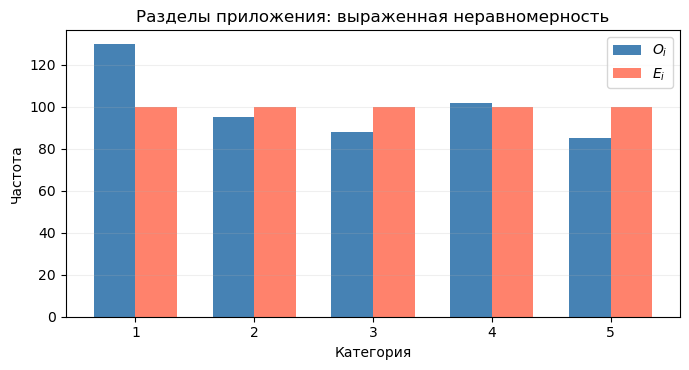

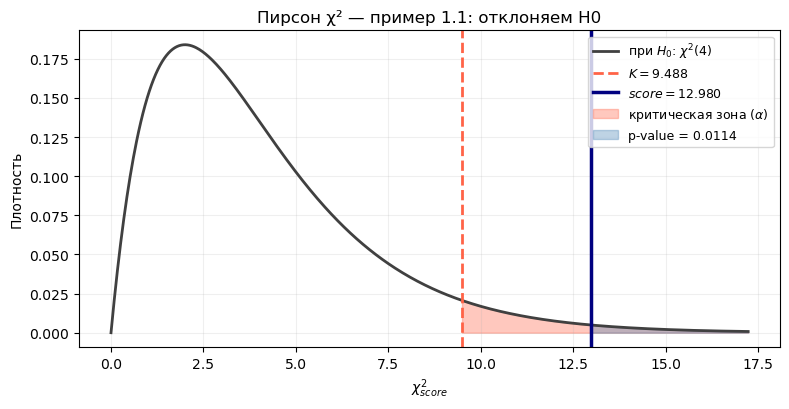

score = 12.9800
p-value = 0.011374
Правило: отклоняем H0, если score > 9.488
Решение: Отклоняем H0


In [2]:
run_chi2(
    observed=[130, 95, 88, 102, 85],
    expected=[100, 100, 100, 100, 100],
    example_title='Пирсон χ² — пример 1.1: отклоняем H0',
    data_title='Разделы приложения: выраженная неравномерность',
)

### Пример 1.2 — не отклоняем $H_0$

Частоты близки к ожидаемым: $O = (98, 102, 99, 101, 100)$ — небольшие случайные отклонения при $E_i = 100$.

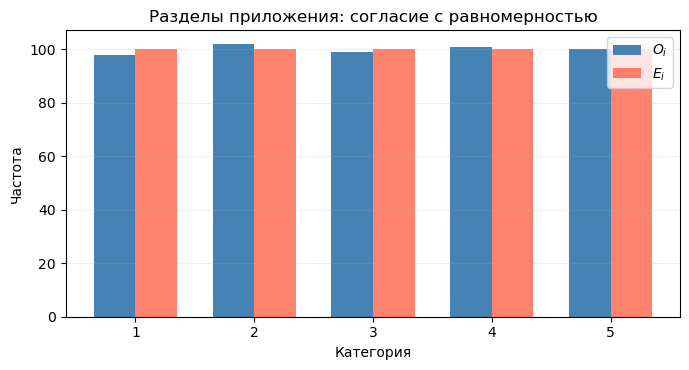

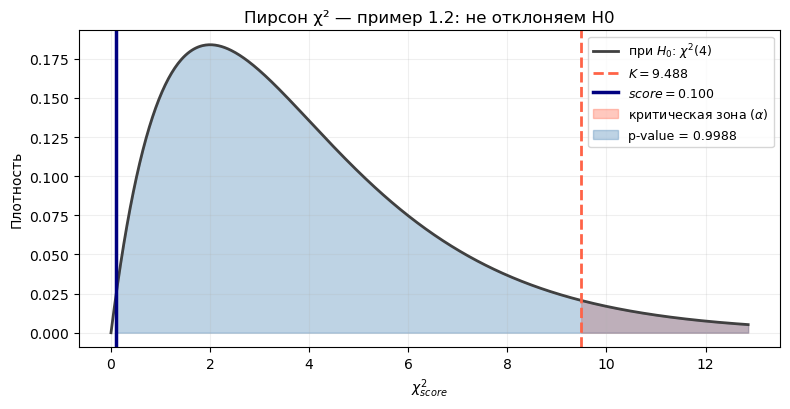

score = 0.1000
p-value = 0.998791
Правило: отклоняем H0, если score > 9.488
Решение: Не отклоняем H0


In [3]:
run_chi2(
    observed=[98, 102, 99, 101, 100],
    expected=[100, 100, 100, 100, 100],
    example_title='Пирсон χ² — пример 1.2: не отклоняем H0',
    data_title='Разделы приложения: согласие с равномерностью',
)

---
## 2. Тест Шапиро–Уилка ($W$)

**Иначе:** проверка нормальности выборки $X_1, \ldots, X_n$.

**Гипотезы:**
- $H_0$: $X_i \sim \mathcal{N}(\mu, \sigma^2)$ для некоторых $\mu, \sigma^2$;
- $H_1$: распределение не нормальное.

**Идея.** Упорядочим выборку: $X_{(1)} \leq \ldots \leq X_{(n)}$. При нормальности вариационный ряд похож на эталонный.

**Статистика:**
$$
W = \frac{\left(\sum_{i=1}^{n} a_i X_{(i)}\right)^2}{\sum_{i=1}^{n}(X_i - \bar{X})^2}, \quad W \in (0, 1].
$$
Коэффициенты $a_i$ зависят только от $n$ (таблицы / `scipy.stats.shapiro`).

**При $H_0$:** $W$ близко к 1; малые $W$ — в левом хвосте.

**Правило:** $P_{H_0}(W < K) = \alpha$, отклоняем $H_0$, если $W_{\text{score}} < W_{(n,\,\alpha)}$.

На графике ниже — **эмпирическое** распределение $W$ при $H_0$ (симуляция нормальных выборок); $K = 0.877$ для $n=15$ — из таблицы лекции.

**Сюжет:** дневные доходности акции (%) перед расчётом доверительных интервалов.

### Пример 2.1 — отклоняем $H_0$

Данные из лекции с выбросами $4.8$ и $5.2\%$.

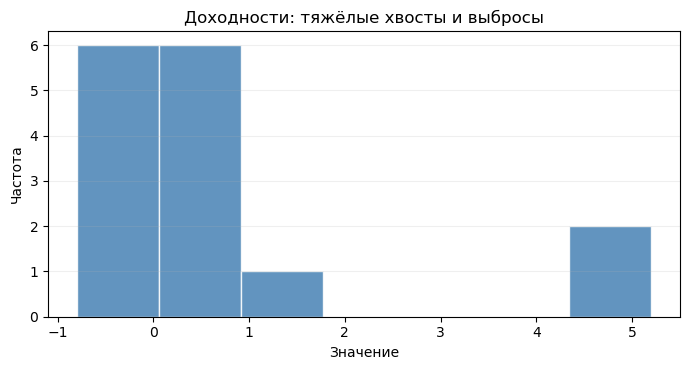

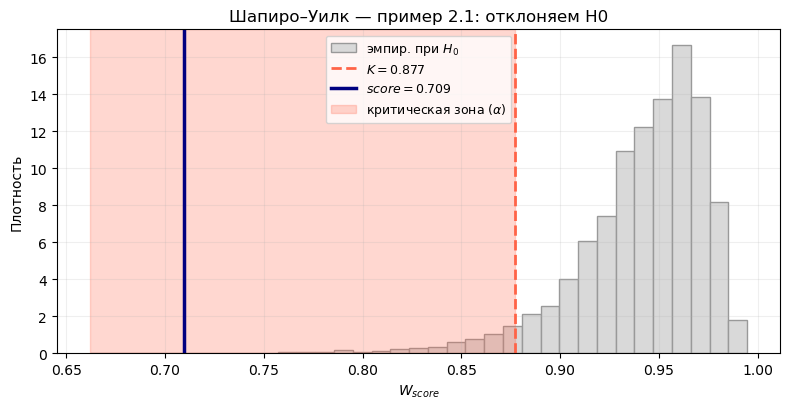

score = 0.7093
p-value = 0.000313
Правило: отклоняем H0, если score < 0.877
Решение: Отклоняем H0


In [4]:
run_shapiro(
    data=[-0.8, -0.5, -0.4, -0.3, -0.2, -0.1, 0.2, 0.3, 0.4, 0.6, 0.8, 0.9, 1.1, 4.8, 5.2],
    W_crit=0.877,
    example_title='Шапиро–Уилк — пример 2.1: отклоняем H0',
    data_title='Доходности: тяжёлые хвосты и выбросы',
)

### Пример 2.2 — не отклоняем $H_0$

Симметричная выборка без выбросов — типичный «колокол».

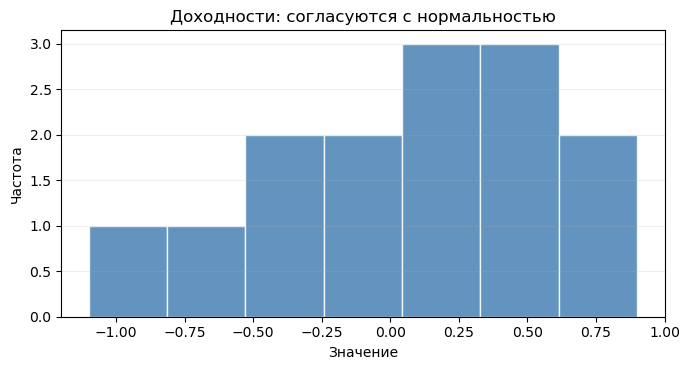

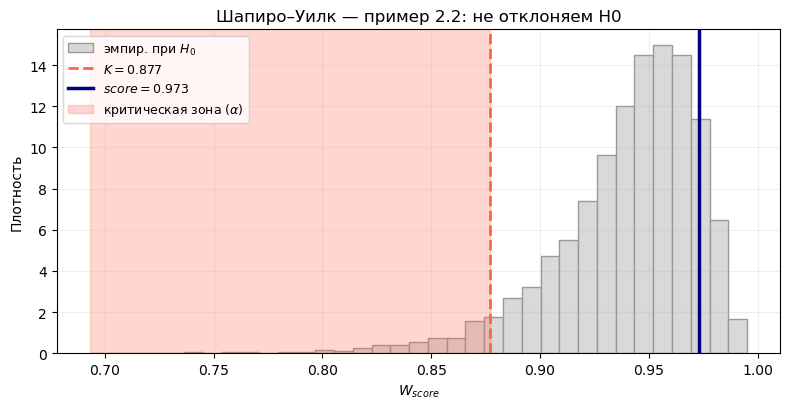

score = 0.9729
p-value = 0.912651
Правило: отклоняем H0, если score < 0.877
Решение: Не отклоняем H0


In [5]:
run_shapiro(
    data=[-1.1, -0.7, -0.4, -0.2, 0.0, 0.3, 0.5, 0.6, 0.8, 0.2, 0.9, 0.4, -0.3, 0.1],
    W_crit=0.877,
    example_title='Шапиро–Уилк — пример 2.2: не отклоняем H0',
    data_title='Доходности: согласуются с нормальностью',
)

---
## 3. Тест Манна–Уитни ($U$)

**Гипотезы (двусторонние):**
- $H_0$: распределения $X$ и $Y$ совпадают;
- $H_1$: распределения различаются.

**Процедура.** Объединяем выборки, ставим ранги $1, \ldots, N$. Суммы рангов $R_X$, $R_Y$:
$$
U_X = R_X - \frac{n(n+1)}{2}, \quad U_Y = R_Y - \frac{m(m+1)}{2}, \quad U_{\text{score}} = \min(U_X, U_Y).
$$


**Правило:** отклоняем $H_0$, если $U_{\text{score}} \leq U_{(n,m,\,\alpha/2)}$. Для $n=m=6$: $K=5$.

**Замечание:** тест наиболее чувствителен к **сдвигу** (одна группа систематически больше), а не к разнице дисперсий при одинаковом центре.

### Визуализация ранжирования

Шаг 1 теста Манна–Уитни: объединить выборки и проранжировать все $N = n + m$ значений.

- **Синий** ($\textcolor{blue}{\mathrm{A}}$) — формат A, **красный** ($\textcolor{red}{\mathrm{B}}$) — формат B.
- Нижний индекс $(i)$ — ранг в объединённом ряду.

Если распределения **сильно различаются**, ранги групп **не перемешиваются** (два блока) → $U_{score}$ мало.

Если распределения **похожи**, ранги **перемежаются** → $U_{score}$ близок к центру null-распределения.

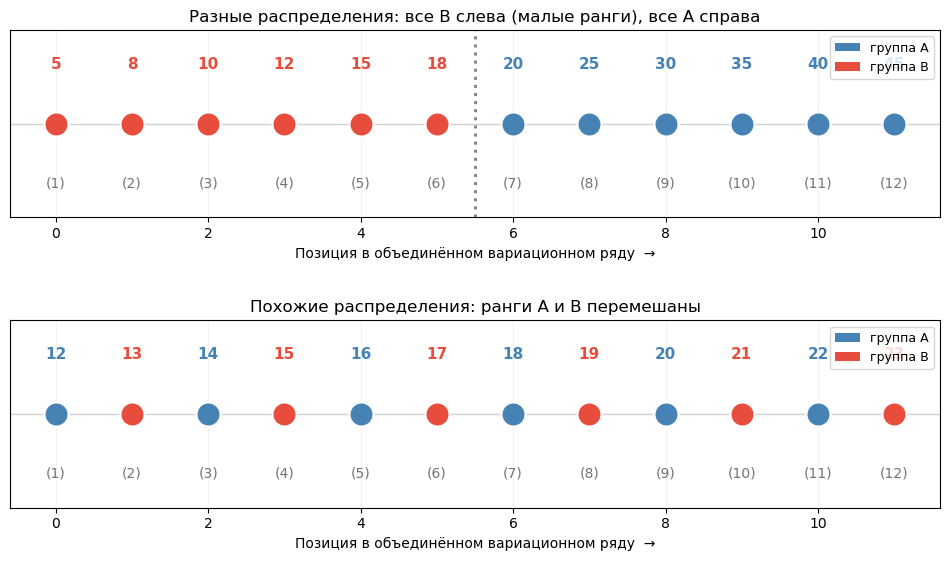

**Разные распределения: все B слева (малые ранги), все A справа:**

$$\textcolor{red}{5}_{(1)}\;\textcolor{red}{8}_{(2)}\;\textcolor{red}{10}_{(3)}\;\textcolor{red}{12}_{(4)}\;\textcolor{red}{15}_{(5)}\;\textcolor{red}{18}_{(6)}\;\textcolor{blue}{20}_{(7)}\;\textcolor{blue}{25}_{(8)}\;\textcolor{blue}{30}_{(9)}\;\textcolor{blue}{35}_{(10)}\;\textcolor{blue}{40}_{(11)}\;\textcolor{blue}{45}_{(12)}$$

**Похожие распределения: ранги A и B перемешаны:**

$$\textcolor{blue}{12}_{(1)}\;\textcolor{red}{13}_{(2)}\;\textcolor{blue}{14}_{(3)}\;\textcolor{red}{15}_{(4)}\;\textcolor{blue}{16}_{(5)}\;\textcolor{red}{17}_{(6)}\;\textcolor{blue}{18}_{(7)}\;\textcolor{red}{19}_{(8)}\;\textcolor{blue}{20}_{(9)}\;\textcolor{red}{21}_{(10)}\;\textcolor{blue}{22}_{(11)}\;\textcolor{red}{23}_{(12)}$$

In [2]:
compare_mw_rankings(
    case1=(
        [20, 25, 30, 35, 40, 45],
        [5, 8, 10, 12, 15, 18],
        'Разные распределения: все B слева (малые ранги), все A справа',
    ),
    case2=(
        [12, 14, 16, 18, 20, 22],
        [13, 15, 17, 19, 21, 23],
        'Похожие распределения: ранги A и B перемешаны',
    ),
)

### Пример 3.1 — отклоняем $H_0$

Формат B заметно быстрее: $A = (20,\ldots,45)$, $B = (5,8,10,12,15,18)$ — из лекции.

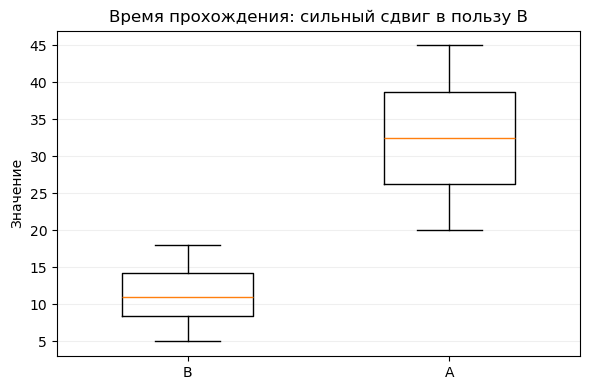

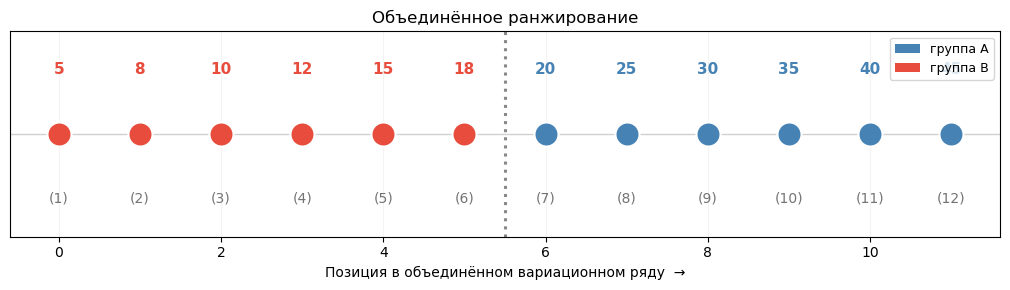

**Упорядоченный ряд** ($\textcolor{blue}{\mathrm{A}}$ — синий, $\textcolor{red}{\mathrm{B}}$ — красный; нижний индекс — ранг):

$$\textcolor{red}{5}_{(1)}\;\textcolor{red}{8}_{(2)}\;\textcolor{red}{10}_{(3)}\;\textcolor{red}{12}_{(4)}\;\textcolor{red}{15}_{(5)}\;\textcolor{red}{18}_{(6)}\;\textcolor{blue}{20}_{(7)}\;\textcolor{blue}{25}_{(8)}\;\textcolor{blue}{30}_{(9)}\;\textcolor{blue}{35}_{(10)}\;\textcolor{blue}{40}_{(11)}\;\textcolor{blue}{45}_{(12)}$$

Сумма рангов: R_A = 57, R_B = 21
U_X = 36, U_Y = 0, U_score = 0


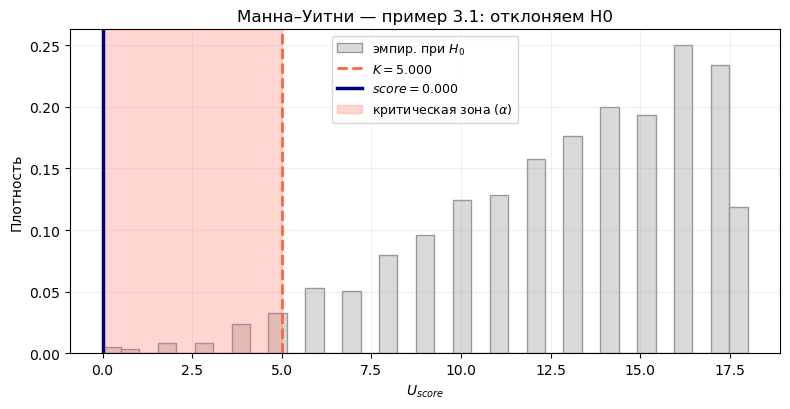

score = 0.0000
p-value = 0.002165
Правило: отклоняем H0, если score < 5.000
Решение: Отклоняем H0


In [7]:
run_mann_whitney(
    group_a=[20, 25, 30, 35, 40, 45],
    group_b=[5, 8, 10, 12, 15, 18],
    u_crit=5,
    example_title='Манна–Уитни — пример 3.1: отклоняем H0',
    data_title='Время прохождения: сильный сдвиг в пользу B',
)

### Пример 3.2 — не отклоняем $H_0$

Группы перекрываются: $A = (12,14,16,18,20,22)$, $B = (13,15,17,19,21,23)$ — сдвиг есть, но слабый относительно разброса рангов.

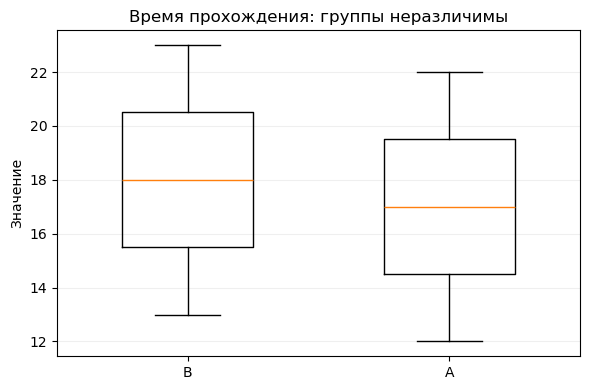

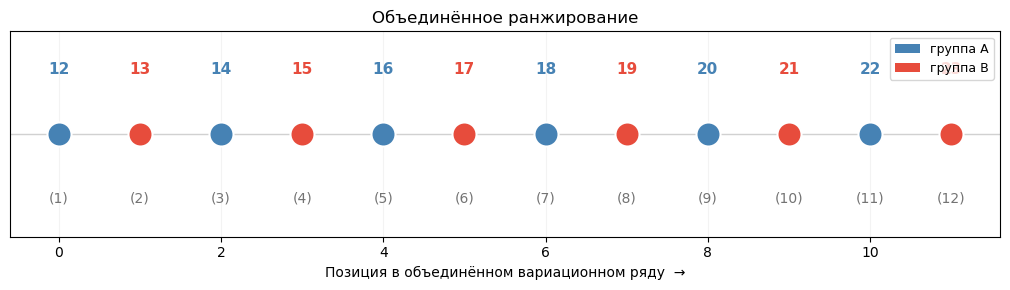

**Упорядоченный ряд** ($\textcolor{blue}{\mathrm{A}}$ — синий, $\textcolor{red}{\mathrm{B}}$ — красный; нижний индекс — ранг):

$$\textcolor{blue}{12}_{(1)}\;\textcolor{red}{13}_{(2)}\;\textcolor{blue}{14}_{(3)}\;\textcolor{red}{15}_{(4)}\;\textcolor{blue}{16}_{(5)}\;\textcolor{red}{17}_{(6)}\;\textcolor{blue}{18}_{(7)}\;\textcolor{red}{19}_{(8)}\;\textcolor{blue}{20}_{(9)}\;\textcolor{red}{21}_{(10)}\;\textcolor{blue}{22}_{(11)}\;\textcolor{red}{23}_{(12)}$$

Сумма рангов: R_A = 36, R_B = 42
U_X = 15, U_Y = 21, U_score = 15


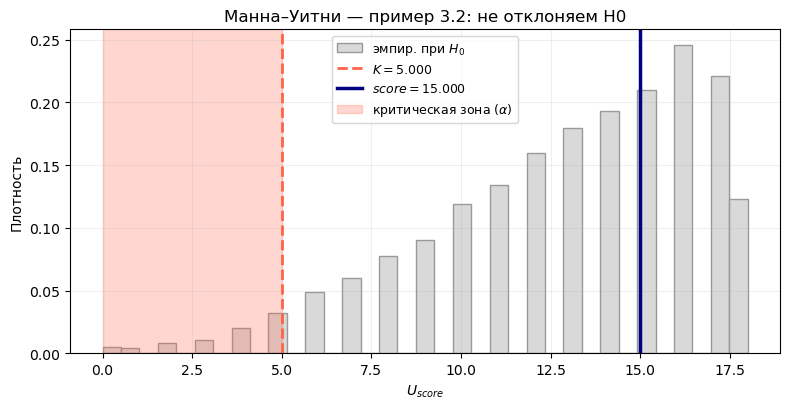

score = 15.0000
p-value = 0.699134
Правило: отклоняем H0, если score < 5.000
Решение: Не отклоняем H0


In [8]:
run_mann_whitney(
    group_a=[12, 14, 16, 18, 20, 22],
    group_b=[13, 15, 17, 19, 21, 23],
    u_crit=5,
    example_title='Манна–Уитни — пример 3.2: не отклоняем H0',
    data_title='Время прохождения: группы неразличимы',
)

---
## 4. Тест значимости корреляции Пирсона ($t$)

**Не путать** с критерием согласия Пирсона ($\chi^2$): здесь — линейная связь двух количественных признаков.

**Парные данные** $(X_i, Y_i)$, $i=1,\ldots,n$.

**Гипотезы:** $H_0: \rho = 0$ против $H_1: \rho \neq 0$.

**Выборочная корреляция:**
$$
r = \frac{\sum_{i=1}^{n}(x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i=1}^{n}(x_i - \bar{x})^2 \sum_{i=1}^{n}(y_i - \bar{y})^2}}.
$$

**При $H_0$** (двумерная нормальность):
$$
t_{\text{score}} = \frac{r\sqrt{n-2}}{\sqrt{1-r^2}} \sim t_{(n-2)}.
$$

**Правило:** отклоняем $H_0$, если $|t_{\text{score}}| > t_{(n-2,\,\alpha/2)}$.

**Сюжет:** часы подготовки к экзамену и итоговый балл, $n=10$.

### Пример 4.1 — отклоняем $H_0$

Явная положительная линейная связь (данные лекции): $r \approx 0.87$.

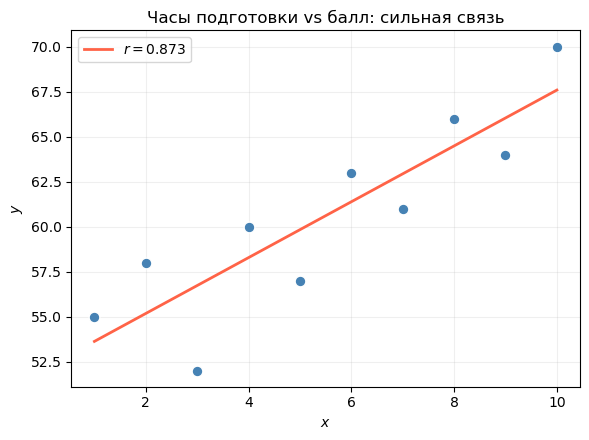

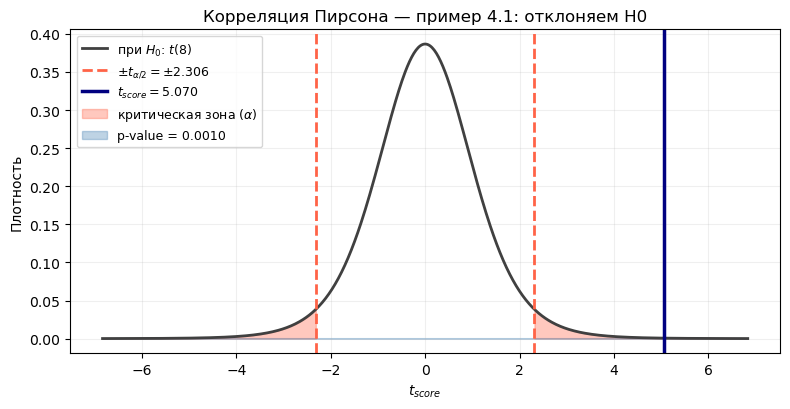

score = 5.0701
p-value = 0.000965
Правило: отклоняем H0, если |t_score| > 2.306
Решение: Отклоняем H0


In [9]:
run_correlation(
    x=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    y=[55, 58, 52, 60, 57, 63, 61, 66, 64, 70],
    example_title='Корреляция Пирсона — пример 4.1: отклоняем H0',
    data_title='Часы подготовки vs балл: сильная связь',
)

### Пример 4.2 — не отклоняем $H_0$

Баллы почти не зависят от часов: $r \approx 0.02$.

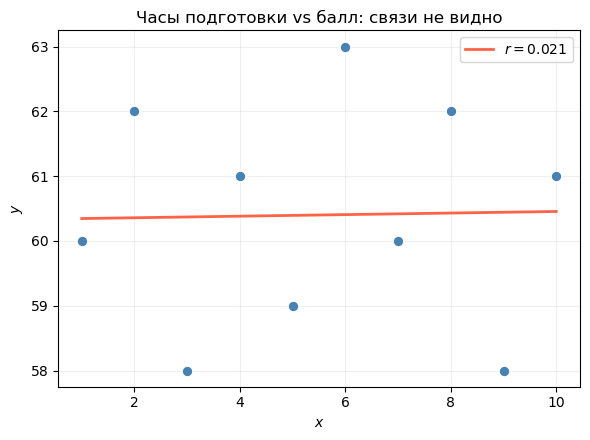

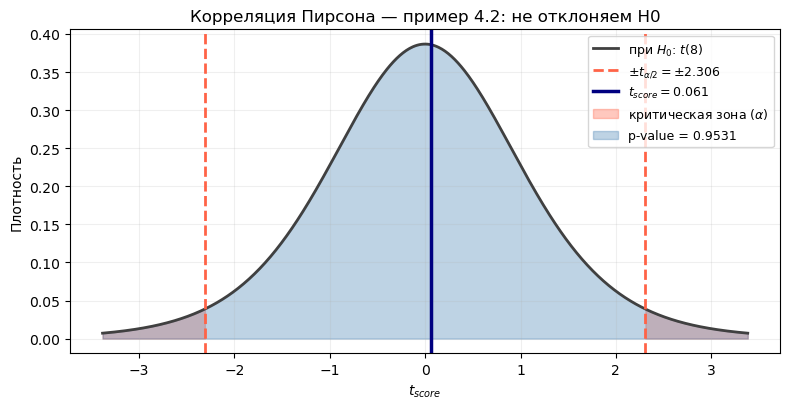

score = 0.0606
p-value = 0.953149
Правило: отклоняем H0, если |t_score| > 2.306
Решение: Не отклоняем H0


In [ ]:
run_correlation(
    x=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    y=[60, 62, 58, 61, 59, 63, 60, 62, 58, 61],
    example_title='Корреляция Пирсона — пример 4.2: не отклоняем H0',
    data_title='Часы подготовки vs балл: связи не видно',
)

---
## Итоги

| Тест | $H_0$ | Статистика | Критическая область |
|------|-------|------------|---------------------|
| Пирсон $\chi^2$ | $p_i$ заданы | $\chi^2_{\text{score}}$ | правый хвост |
| Шапиро–Уилк | нормальность | $W$ | левый хвост |
| Манна–Уитни | $F_X = F_Y$ | $U_{\text{score}}$ | левый хвост (двусторонний) |
| Корреляция Пирсона | $\rho = 0$ | $t_{\text{score}}$ | оба хвоста $t_{(n-2)}$ |